In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib
print(matplotlib.__version__)

3.11.2


In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path


# Phase 2: Exploratory Data Analysis, IndiaKart (24-Jun-2023 to 23-Jun-2025)

**How the charts were built**
- **Revenue excludes Cancelled orders.** Cancelled orders still show a successful payment (see the Phase 1 report), so counting them would overstate revenue. Total revenue is ₹277.9 crore. Order counts (charts 1, 4, 5 and 7) use all 50,000 orders.
- **The data covers 25 calendar months, not 24.** It starts on 24-Jun-2023 and ends on 23-Jun-2025, so June 2023 (7 days) and June 2025 (23 days) are partial months. They are hatched in chart 1, and the year-over-year comparison in chart 2 uses Jul–Jun years.
- **Chart 3 covers only orders with line items.** 20% of orders have no line items (see the Phase 1 report), so its total (₹252.7 crore) is lower than the order-level total (₹277.9 crore).
- **Segments** use the original `segment` column of the customers table, which matches the PRD's Premium, Regular and Budget wording.

In [4]:
OUT=Path("charts");OUT.mkdir(exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(OUT / name , dpi=150, bbox_inches="tight")
    plt.show()

In [5]:
orders    = pd.read_csv("orders_clean.csv", parse_dates=["order_date"])
customers = pd.read_csv("customers_clean_v2.csv")
items     = pd.read_csv("order_items_clean.csv")
returns   = pd.read_csv("returns_clean.csv")

In [6]:
orders["month"] = orders["order_date"].dt.to_period("M")
PARTIAL = {pd.Period("2023-06"), pd.Period("2025-06")}
valid_orders = orders[orders["status"] != "Cancelled"]
BLUE, RED = "#4c78a8", "#d62728"

print(orders.shape, customers.shape, items.shape, returns.shape)
print(orders["order_date"].min(), orders["order_date"].max())
print(len(valid_orders))

(50000, 21) (10000, 21) (100000, 11) (10000, 14)
2023-06-24 00:00:00 2025-06-23 00:00:00
44004


In [7]:
print(orders.columns.tolist())

['Unnamed: 0', 'order_id', 'customer_id', 'order_date', 'order_time', 'status', 'city', 'state', 'pincode', 'total_amount', 'gst_amount', 'shipping_charge', 'discount_amount', 'final_amount', 'payment_method', 'shipping_partner', 'tracking_id', 'delivered_date', 'is_cod', 'channel', 'month']


In [8]:
files = ["customers_clean.csv", "customers_clean_v2.csv", "products_clean.csv", "orders_clean.csv",
         "orders_clean_flagged.csv", "order_items_clean.csv", "payments_clean.csv",
         "returns_clean.csv", "inventory_clean.csv", "suppliers_clean.csv"]
for f in files:
    cols = pd.read_csv(f, nrows=1).columns.tolist()
    n = len(cols)
    print(f, n, "UNNAMED COLUMN" if any(c.startswith("Unnamed") for c in cols) else "ok")

customers_clean.csv 17 ok
customers_clean_v2.csv 21 ok
products_clean.csv 17 ok
orders_clean.csv 20 UNNAMED COLUMN
orders_clean_flagged.csv 22 UNNAMED COLUMN
order_items_clean.csv 11 ok
payments_clean.csv 13 ok
returns_clean.csv 14 ok
inventory_clean.csv 12 ok
suppliers_clean.csv 14 ok


In [9]:
for f in ["orders_clean.csv", "orders_clean_flagged.csv"]:
    cols = pd.read_csv(f, nrows=1).columns.tolist()
    print(f, len(cols), cols[:2], cols[-2:])

orders_clean.csv 20 ['Unnamed: 0', 'order_id'] ['is_cod', 'channel']
orders_clean_flagged.csv 22 ['Unnamed: 0', 'order_id'] ['has_items', 'high_value_order']


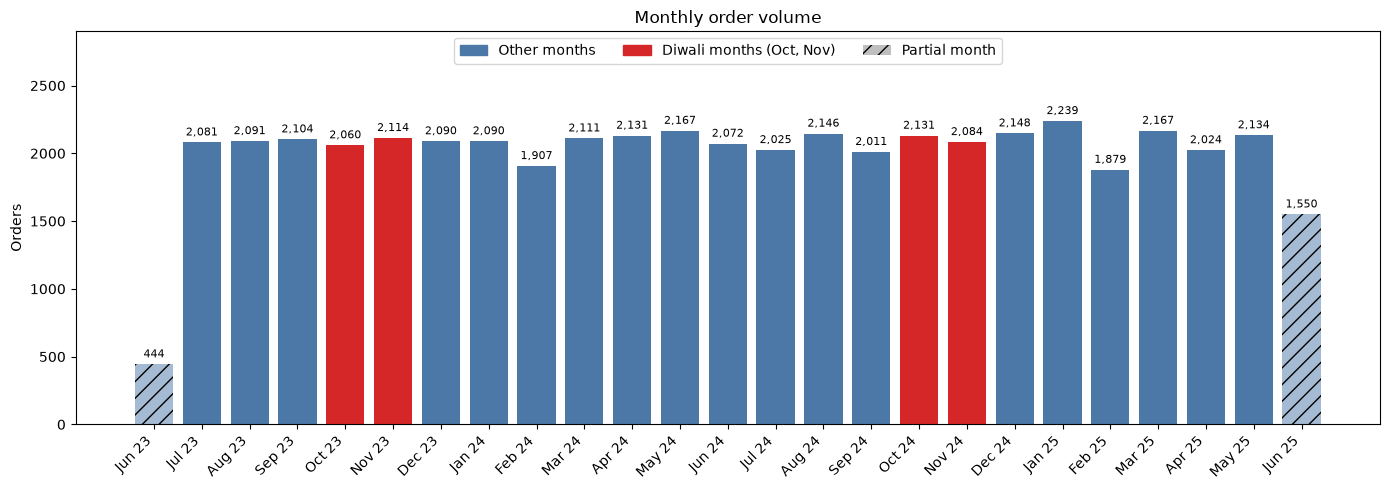

In [10]:
#1.	Monthly order volume 
vol = orders.groupby("month").size()
labels = [p.strftime("%b %y") for p in vol.index]
colors = [RED if p.month in (10, 11) else BLUE for p in vol.index]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(labels, vol.values, color=colors)
for b, p in zip(bars, vol.index):
    if p in PARTIAL:
        b.set_hatch("//"); b.set_alpha(0.5)

ax.bar_label(bars, labels=[f"{v:,}" for v in vol.values], padding=3, fontsize=8)

ax.set_title("Monthly order volume"); ax.set_ylabel("Orders")
plt.xticks(rotation=45, ha="right")
ax.set_ylim(0, 2900)
ax.legend(handles=[Patch(color=BLUE, label="Other months"),
                   Patch(color=RED, label="Diwali months (Oct, Nov)"),
                   Patch(facecolor="grey", hatch="//", alpha=0.5, label="Partial month")],
          loc="upper center", ncol=3)
save("01_monthly_orders.png")

**Observation:** Order volume is flat at roughly 2,000 to 2,200 orders a month across the two years. There is no Diwali uplift: October and November had 2,060 and 2,114 orders in 2023 and 2,131 and 2,084 in 2024, in line with the other months, so the data shows no festive-season effect. February is the lowest full month (1,907 in 2024 and 1,879 in 2025), partly because it is shorter, and June 2023 and June 2025 are low only because the data covers just part of those months (24 June to 30 June 2023, and 1 June to 23 June 2025).

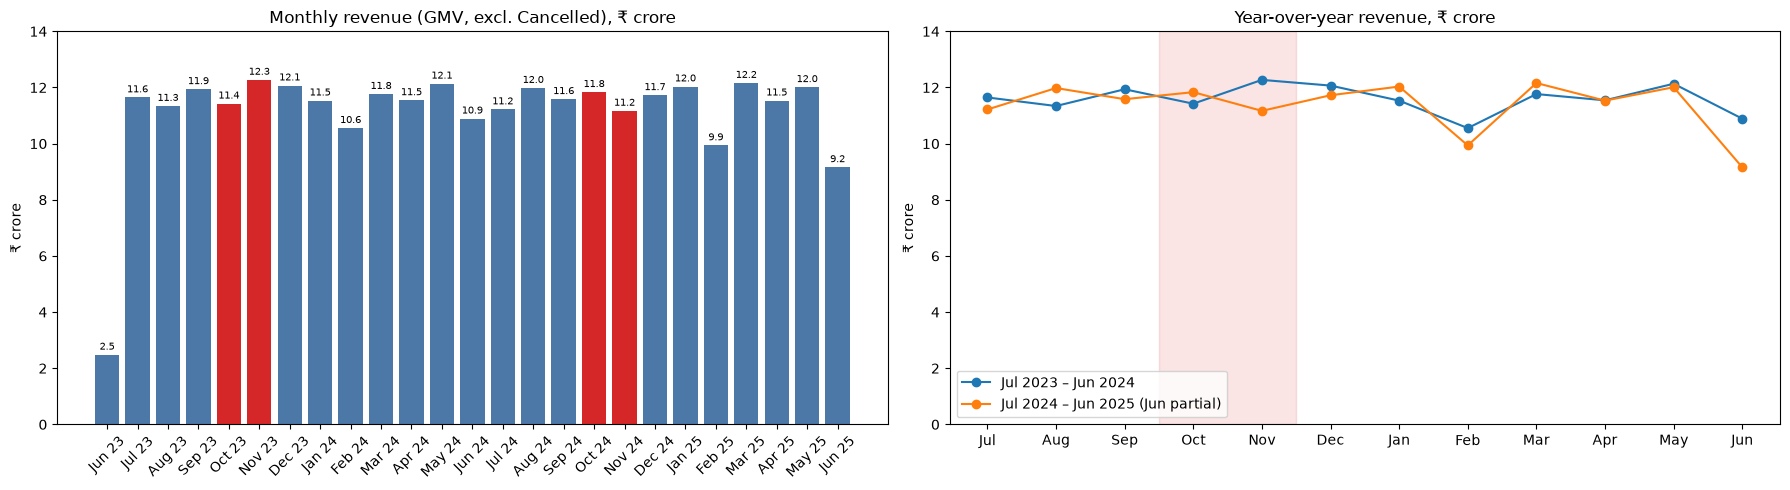

Year totals (₹ crore): 139.1 136.33


In [11]:
#2.	Monthly revenue (GMV)
rev = valid_orders.groupby("month")["final_amount"].sum() / 1e7
rev_all = rev.reindex(vol.index)          # same 25 months, in the same order as chart 1

fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5))

# Left: monthly revenue with value labels
b2 = a1.bar(labels, rev_all.values, color=colors)
a1.bar_label(b2, labels=[f"{v:.1f}" for v in rev_all.values], padding=2, fontsize=7)
a1.set_ylim(0, 14)
a1.set_title("Monthly revenue (GMV, excl. Cancelled), ₹ crore")
a1.set_ylabel("₹ crore")
a1.tick_params(axis="x", rotation=45)

# Right: year-over-year (Jul-Jun years)
y1 = rev[(rev.index >= pd.Period("2023-07")) & (rev.index <= pd.Period("2024-06"))].values
y2 = rev[(rev.index >= pd.Period("2024-07")) & (rev.index <= pd.Period("2025-06"))].values
mon = ["Jul","Aug","Sep","Oct","Nov","Dec","Jan","Feb","Mar","Apr","May","Jun"]
a2.plot(mon, y1, marker="o", label="Jul 2023 – Jun 2024")
a2.plot(mon, y2, marker="o", label="Jul 2024 – Jun 2025 (Jun partial)")
a2.axvspan(2.5, 4.5, color=RED, alpha=0.12)
a2.set_ylim(0, 14)
a2.set_title("Year-over-year revenue, ₹ crore")
a2.set_ylabel("₹ crore")
a2.legend(loc="lower left")

save("02_monthly_revenue.png")
print("Year totals (₹ crore):", round(y1.sum(), 2), round(y2.sum(), 2))

**Observation:** Revenue (excluding cancelled orders) totals ₹277.9 crore, running at about ₹10 to ₹12.3 crore a month. The peak is November 2023 (₹12.27 crore), but there is no consistent festive lift: Oct and Nov 2024 came in at ₹11.83 and ₹11.17 crore, and November 2024 is below November 2023. Year over year, Jul 2023–Jun 2024 brought in ₹139.1 crore against ₹136.3 crore for Jul 2024–Jun 2025 (down 2.0%), but most of that gap is June 2025, which covers only 23 days (₹9.16 crore against ₹10.89 crore for the full June 2024); excluding June, the change is about −0.8%, so revenue is essentially flat. February is the weakest month in both years (₹10.55 and ₹9.94 crore).

category
Electronics         145.46
Sports & Fitness     43.61
Home & Kitchen       21.56
Fashion              13.12
Automotive           10.87
Office Supplies       8.19
Toys & Baby           4.06
Beauty & Health       2.92
Grocery               1.64
Books                 1.23
Name: total_price, dtype: float64
category
Electronics         57.6
Sports & Fitness    17.3
Home & Kitchen       8.5
Fashion              5.2
Automotive           4.3
Office Supplies      3.2
Toys & Baby          1.6
Beauty & Health      1.2
Grocery              0.7
Books                0.5
Name: total_price, dtype: float64
Total (₹ crore): 252.66


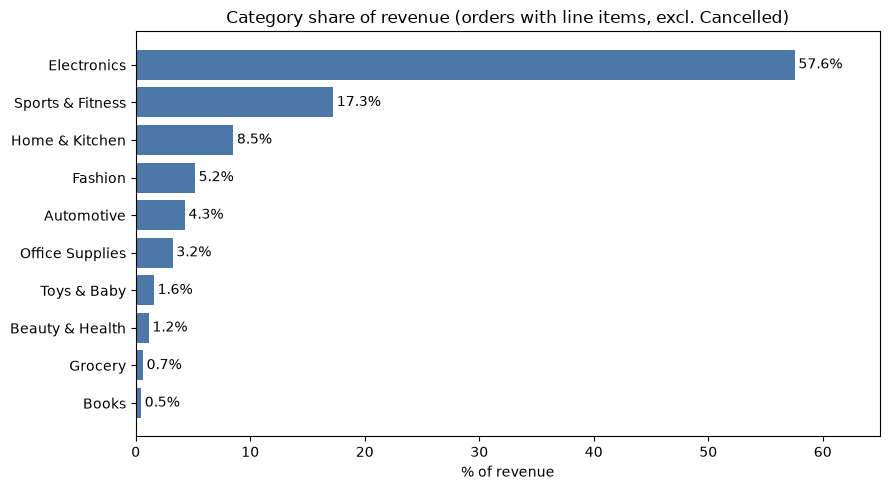

In [12]:
#3.	Category-wise revenue share 
cat = items[items["order_id"].isin(valid_orders["order_id"])].groupby("category")["total_price"].sum().sort_values()
share = cat / cat.sum() * 100

print((cat / 1e7).round(2).sort_values(ascending=False))
print(share.round(1).sort_values(ascending=False))
print("Total (₹ crore):", round(cat.sum() / 1e7, 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(share.index, share.values, color=BLUE)
for i, v in enumerate(share.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set_title("Category share of revenue (orders with line items, excl. Cancelled)")
ax.set_xlabel("% of revenue")
ax.set_xlim(0, 65)
save("03_category_revenue_share.png")

**Observation:** Electronics earns the most by a wide margin: ₹145.5 crore, or 57.6% of revenue. Sports & Fitness is second at 17.3%, so the two categories together bring in about three quarters (74.9%) of revenue. At the bottom, Books (0.5%) and Grocery (0.7%) contribute almost nothing. Revenue is far more concentrated than sales volume, because each category has about the same number of line items (roughly 9,800 to 10,150 each), so the gap comes from price per item. This chart covers only orders with line items (₹252.7 crore, against ₹277.9 crore of total revenue), because 20% of orders have no line items.

status
Delivered     32499
Cancelled      5996
Shipped        5071
Returned       3933
Processing     2501
Name: count, dtype: int64
status
Delivered     65.0
Cancelled     12.0
Shipped       10.1
Returned       7.9
Processing     5.0
Name: count, dtype: float64


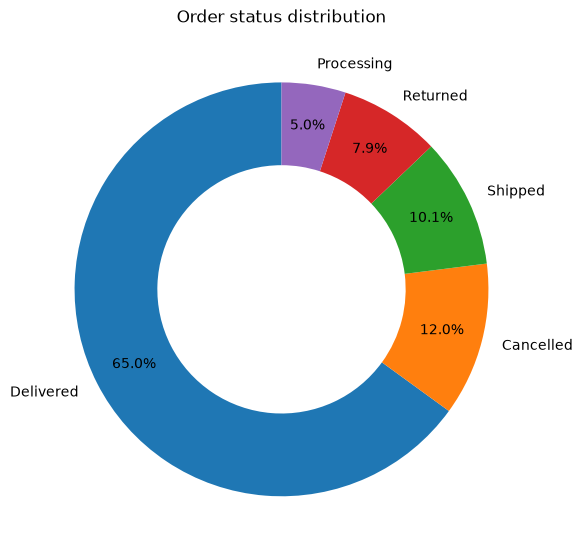

In [13]:
#4.	Order status distribution 
st = orders["status"].value_counts()
print(st)
print((st / len(orders) * 100).round(1))

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(st.values, labels=st.index, autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(width=0.4), pctdistance=0.8)
ax.set_title("Order status distribution")
save("04_order_status_donut.png")

**Observation:** Two thirds of orders (65.0%) end as Delivered. Another 12.0% are Cancelled and 7.9% are Returned, so about one order in five (19.9%) does not end as a completed sale. A further 15.1% are still in progress (Shipped 10.1%, Processing 5.0%). Note that the Returned slice counts only orders with status Returned; the returns table has many more return records, because returns are also logged against Delivered, Cancelled and Shipped orders.

state
Uttar Pradesh     9507
Maharashtra       8179
Gujarat           3811
Madhya Pradesh    3741
Tamil Nadu        3664
Karnataka         3102
Rajasthan         3047
West Bengal       2103
Punjab            2073
Jharkhand         2044
Name: count, dtype: int64
States in orders: 18
Top 10 share of orders: 82.5 %
Top 2 share of orders: 35.4 %


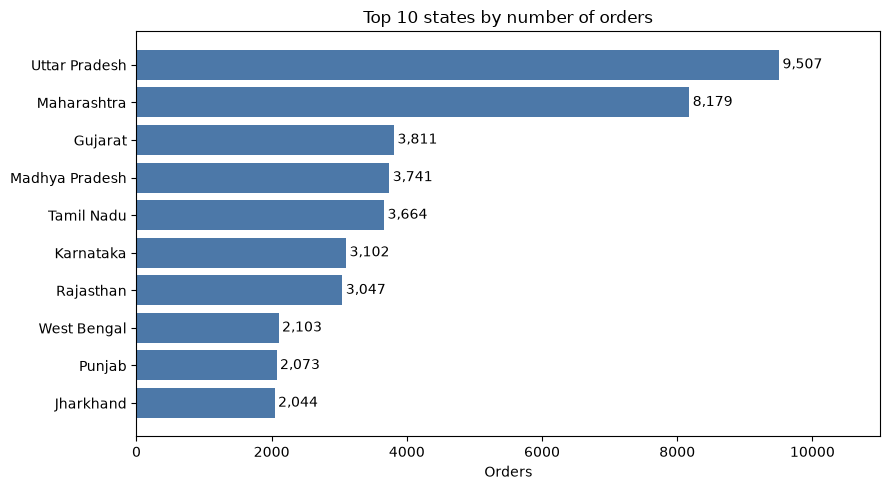

In [14]:
#5.	Top 10 states by number of orders 
states_all = orders["state"].value_counts()
print(states_all.head(10))
print("States in orders:", states_all.shape[0])
print("Top 10 share of orders:", round(states_all.head(10).sum() / len(orders) * 100, 1), "%")
print("Top 2 share of orders:", round(states_all.head(2).sum() / len(orders) * 100, 1), "%")

states = states_all.head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(states.index, states.values, color=BLUE)
for i, v in enumerate(states.values):
    ax.text(v + 50, i, f"{v:,}", va="center")
ax.set_title("Top 10 states by number of orders")
ax.set_xlabel("Orders")
ax.set_xlim(0, 11000)
save("05_top_states.png")

**Observation:** Orders are heavily concentrated in two states. Uttar Pradesh (9,507) and Maharashtra (8,179) together account for 35.4% of all orders, and each has more than twice as many orders as third-placed Gujarat (3,811). Gujarat, Madhya Pradesh (3,741) and Tamil Nadu (3,664) form a close middle group, followed by Karnataka and Rajasthan at about 3,000. The top 10 states generate 82.5% of orders, out of 18 states in total, so growth in the largest states matters most for overall volume.

segment
Regular     4026
Budget      2505
Premium     1501
New         1488
Inactive     480
Name: count, dtype: int64
segment
Regular     40.3
Budget      25.0
Premium     15.0
New         14.9
Inactive     4.8
Name: count, dtype: float64


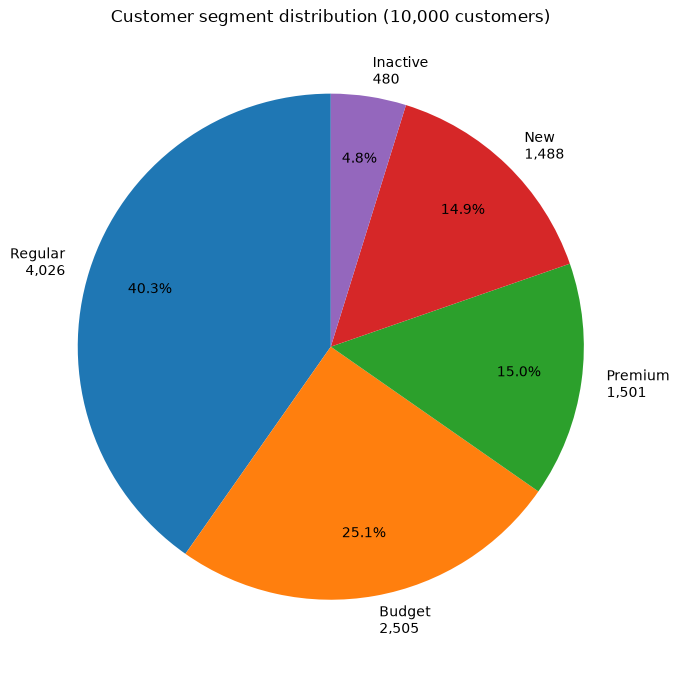

In [15]:
#6.	Customer segment distribution 
seg = customers["segment"].value_counts()
print(seg)
print((seg / len(customers) * 100).round(1))

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(seg.values,
       labels=[f"{name}\n{count:,}" for name, count in seg.items()],
       autopct="%1.1f%%", startangle=90, pctdistance=0.75)
ax.set_title("Customer segment distribution (10,000 customers)")
save("06_customer_segments.png")

**Observation:** Regular customers are the largest group (4,026, 40.3%), followed by Budget (2,505, about 25%) and Premium (1,501, 15.0%). Premium customers are the smallest of the three main tiers: there are about 2.7 times as many Regular customers as Premium ones. New customers make up 14.9% (1,488) and Inactive customers 4.8% (480). The distribution matches the shares described in the data dictionary.

payment_method
UPI                 17570
Credit Card         10007
Debit Card           7624
Cash on Delivery     5883
Net Banking          4026
EMI                  2943
Wallet               1947
Name: count, dtype: int64
payment_method
UPI                 35.1
Credit Card         20.0
Debit Card          15.2
Cash on Delivery    11.8
Net Banking          8.1
EMI                  5.9
Wallet               3.9
Name: count, dtype: float64
Paid online (not COD): 88.2 %


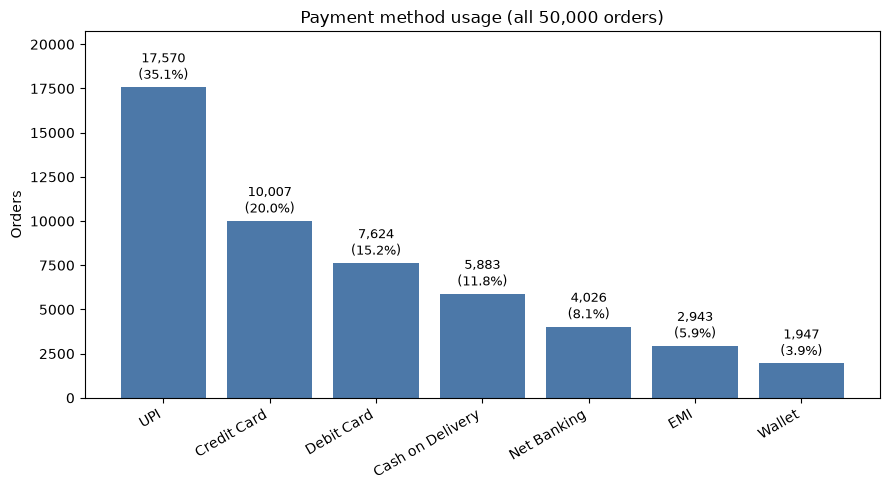

In [16]:
#7.	Payment method usage 
pm = orders["payment_method"].value_counts()
print(pm)
print((pm / len(orders) * 100).round(1))
print("Paid online (not COD):", round((1 - pm["Cash on Delivery"] / len(orders)) * 100, 1), "%")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(pm.index, pm.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:,}\n({v/len(orders)*100:.1f}%)" for v in pm.values], padding=3, fontsize=9)
ax.set_ylim(0, pm.max() * 1.18)
ax.set_title("Payment method usage (all 50,000 orders)")
ax.set_ylabel("Orders")
plt.xticks(rotation=30, ha="right")
save("07_payment_methods.png")

**Observation:** UPI is the most popular payment method, used for 35.1% of orders (17,570). Credit Card (20.0%) and Debit Card (15.2%) follow, so cards together account for 35.3% and match UPI. Cash on Delivery is used for 11.8% of orders (5,883), which means 88.2% of orders are paid online. Wallets (3.9%) and EMI (5.9%) are the least used.

count    10000.0
mean        41.7
std         13.8
min         18.0
25%         30.0
50%         42.0
75%         54.0
max         65.0
Name: age, dtype: float64
{'18-23': np.int64(1223), '24-29': np.int64(1205), '30-35': np.int64(1274), '36-41': np.int64(1294), '42-47': np.int64(1214), '48-53': np.int64(1227), '54-59': np.int64(1281), '60-65': np.int64(1282)}


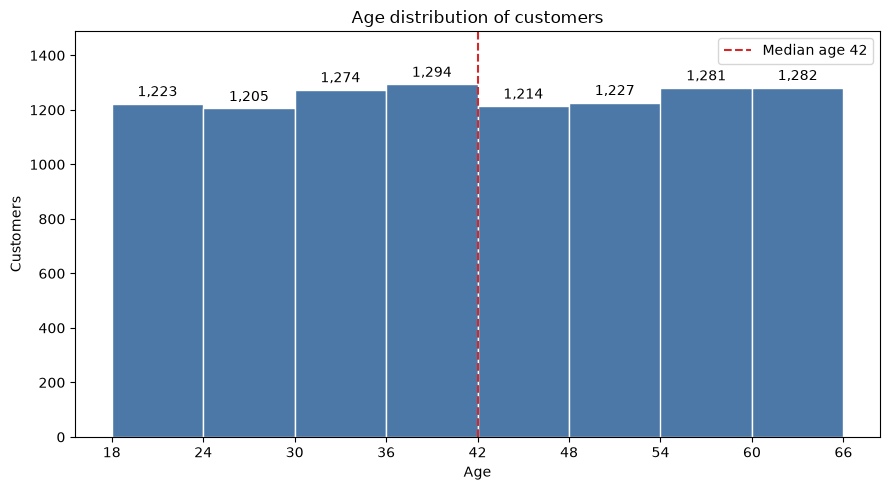

In [17]:
#8.	Age distribution of customers 
print(customers["age"].describe().round(1))

edges = list(range(18, 67, 6))          # 18, 24, 30, ... 66  -> eight bands of six ages each
fig, ax = plt.subplots(figsize=(9, 5))
n, b, patches = ax.hist(customers["age"], bins=edges, color=BLUE, edgecolor="white")
print(dict(zip([f"{lo}-{hi-1}" for lo, hi in zip(edges[:-1], edges[1:])], n.astype(int))))

ax.bar_label(patches, labels=[f"{int(v):,}" for v in n], padding=3)
ax.axvline(customers["age"].median(), color=RED, ls="--", label=f"Median age {customers['age'].median():.0f}")
ax.set_xticks(edges)
ax.set_ylim(0, n.max() * 1.15)
ax.set_title("Age distribution of customers")
ax.set_xlabel("Age"); ax.set_ylabel("Customers"); ax.legend()
save("08_age_distribution.png")

**Observation:** Customers range from 18 to 65 years old, with a mean of 41.7 and a median of 42. The distribution is almost flat: every six-year age band holds between 1,205 and 1,294 customers, so no age group stands out as the largest. This chart counts customers, not orders or spend, so on its own it cannot say which age group shops the most (see the table below).

In [18]:
bands = list(range(18, 67, 6))
names = [f"{lo}-{hi-1}" for lo, hi in zip(bands[:-1], bands[1:])]
customers["age_band"] = pd.cut(customers["age"], bins=bands, right=False, labels=names)

m = valid_orders.merge(customers[["customer_id", "age_band"]], on="customer_id")
by_age = m.groupby("age_band", observed=True).agg(
    orders=("order_id", "count"),
    revenue_cr=("final_amount", lambda s: s.sum() / 1e7))
by_age["customers"] = customers.groupby("age_band", observed=True).size()
by_age["orders_per_customer"] = (by_age["orders"] / by_age["customers"]).round(2)
print(by_age.round(2))

          orders  revenue_cr  customers  orders_per_customer
age_band                                                    
18-23       5334       33.53       1223                 4.36
24-29       5181       32.62       1205                 4.30
30-35       5567       33.99       1274                 4.37
36-41       5740       37.06       1294                 4.44
42-47       5214       32.67       1214                 4.29
48-53       5472       35.26       1227                 4.46
54-59       5648       35.39       1281                 4.41
60-65       5848       37.38       1282                 4.56


#What age group shops most?          

By orders and revenue, the 60-65 band is highest (5,848 orders, ₹37.4 crore) and 24-29 lowest (5,181 orders, ₹32.6 crore), but the gap is small: orders per customer range only from 4.3 to 4.6, so age is not a strong driver of buying.

reason
Size Issue                 1196
Changed Mind               1150
Damaged in Transit         1143
Wrong Product Delivered    1135
Defective Product          1134
Not as Described           1125
Duplicate Order            1081
Quality Issue              1075
Delayed Delivery            484
Better Price Found          477
Name: count, dtype: int64
reason
Size Issue                 12.0
Changed Mind               11.5
Damaged in Transit         11.4
Wrong Product Delivered    11.4
Defective Product          11.3
Not as Described           11.2
Duplicate Order            10.8
Quality Issue              10.8
Delayed Delivery            4.8
Better Price Found          4.8
Name: count, dtype: float64
Product/fulfilment reasons: 5612 returns = 56.1 %


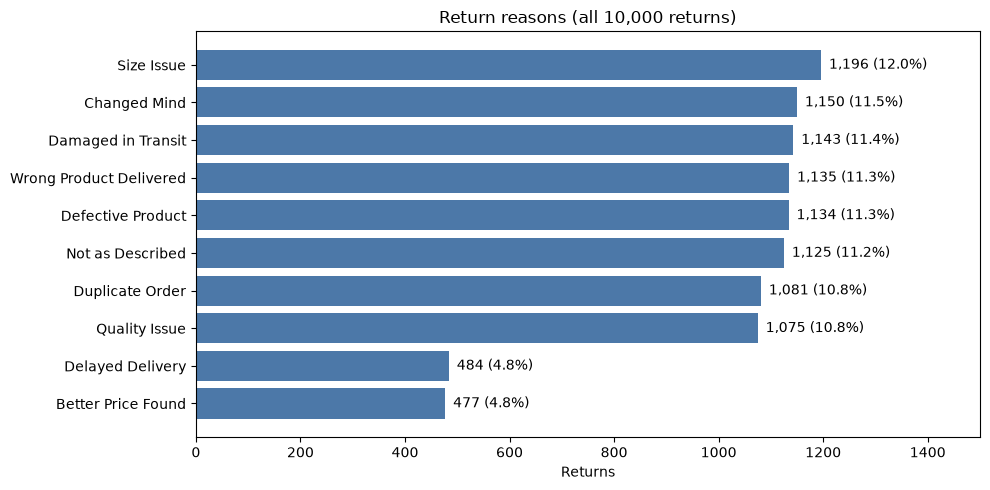

In [19]:
#9.	Return reasons 
rr = returns["reason"].value_counts()
print(rr)
print((rr / len(returns) * 100).round(1))

product_issues = ["Damaged in Transit", "Wrong Product Delivered", "Defective Product", "Not as Described", "Quality Issue"]
print("Product/fulfilment reasons:", rr[product_issues].sum(), "returns =", round(rr[product_issues].sum() / len(returns) * 100, 1), "%")

rs = rr.sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(rs.index, rs.values, color=BLUE)
for i, v in enumerate(rs.values):
    ax.text(v + 15, i, f"{v:,} ({v/len(returns)*100:.1f}%)", va="center")
ax.set_xlim(0, 1500)
ax.set_title("Return reasons (all 10,000 returns)")
ax.set_xlabel("Returns")
save("09_return_reasons.png")

**Observation:** Returns are spread almost evenly across eight of the ten reasons, each accounting for 10.8% to 12.0% of returns; Size Issue is the most common (1,196, 12.0%) and Quality Issue the least among them (1,075, 10.8%). Delayed Delivery (484) and Better Price Found (477) are the rarest, at 4.8% each. Grouping the five reasons that point to a product or fulfilment problem (damaged in transit, wrong product delivered, defective product, not as described, quality issue), they account for 5,612 returns, or 56.1% of the total, so more than half of returns look preventable through better quality control and packaging.

             mean   median  count  customers  orders_per_customer
segment                                                          
Premium   62208.0  24248.0  11340       1501                  7.6
Regular   63120.0  23931.0  20323       4026                  5.0
Budget    64474.0  24571.0   6426       2505                  2.6
New       63826.0  24917.0   5677       1488                  3.8
Inactive  59882.0  23977.0    238        480                  0.5


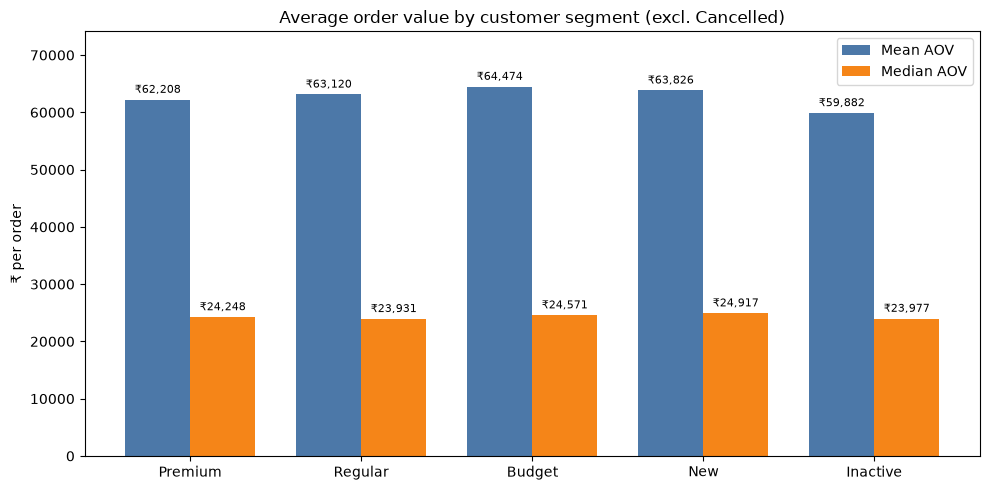

In [20]:
#10.Average Order Value (AOV) by segment 
m = valid_orders.merge(customers[["customer_id", "segment"]], on="customer_id")
order_seg = ["Premium", "Regular", "Budget", "New", "Inactive"]

aov = m.groupby("segment")["final_amount"].agg(["mean", "median", "count"]).reindex(order_seg)
aov["customers"] = customers.groupby("segment").size()
aov["orders_per_customer"] = aov["count"] / aov["customers"]
print(aov.round({"mean": 0, "median": 0, "orders_per_customer": 1}))

x = np.arange(len(aov)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w/2, aov["mean"], w, label="Mean AOV", color=BLUE)
b2 = ax.bar(x + w/2, aov["median"], w, label="Median AOV", color="#f58518")
ax.bar_label(b1, labels=[f"₹{v:,.0f}" for v in aov["mean"]], padding=3, fontsize=8)
ax.bar_label(b2, labels=[f"₹{v:,.0f}" for v in aov["median"]], padding=3, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(aov.index)
ax.set_ylim(0, aov["mean"].max() * 1.15)
ax.set_ylabel("₹ per order"); ax.legend()
ax.set_title("Average order value by customer segment (excl. Cancelled)")
save("10_aov_by_segment.png")

**Observation:** Premium customers do not spend more per order. Mean order value is about ₹60,000 to ₹64,500 in every segment (Premium ₹62,208, slightly below Budget ₹64,474), and the median is about ₹24,000 everywhere, so order size is essentially the same whatever the segment. What differs is how often customers buy: Premium customers placed about 7.6 non-cancelled orders each, against 5.0 for Regular and 2.6 for Budget, so their value comes from frequency, not basket size. Means are roughly 2.5 to 2.6 times the medians because a small number of very large orders pull the average up, and the Inactive figure rests on only 238 orders.

In [21]:
import os
for f in sorted(os.listdir("charts")):
    print(f)

01_monthly_orders.png
02_monthly_revenue.png
03_category_revenue_share.png
04_order_status_donut.png
05_top_states.png
06_customer_segments.png
07_payment_methods.png
08_age_distribution.png
09_return_reasons.png
10_aov_by_segment.png


## Key insights

1. **No festive-season effect.** Oct and Nov orders (2,060 / 2,114 in 2023 and 2,131 / 2,084 in 2024) are in line with the other months, at roughly 2,000 to 2,200 a month. Revenue is also flat, at ₹10–12 crore a month.
2. **Revenue is flat year over year.** Jul 2023–Jun 2024 brought in ₹139.1 crore against ₹136.3 crore for Jul 2024–Jun 2025. Excluding the partial June 2025, the change is about −0.8%.
3. **Revenue is concentrated.** Electronics (57.6%) and Sports & Fitness (17.3%) bring in about three quarters of revenue, and Uttar Pradesh and Maharashtra account for 35.4% of orders.
4. **One order in five does not complete.** 12.0% of orders are Cancelled and 7.9% Returned (19.9% together), and 56.1% of returns cite a product or fulfilment problem (damaged in transit, wrong product, defective, not as described, quality).
5. **Online payments dominate.** UPI is the most used method (35.1%), and 88.2% of orders are paid online rather than by Cash on Delivery.
6. **Premium customers buy more often, not more per order.** Mean order value is about ₹62,000 to ₹64,500 in every segment (Premium ₹62,208, Budget ₹64,474), but Premium customers placed 7.6 orders each against 5.0 for Regular and 2.6 for Budget.
7. **No age group dominates.** Customers are spread evenly across ages 18 to 65, and orders per customer range only from 4.3 to 4.6 across age bands.

**Limitations:** the year-over-year comparison is affected by two partial months, category revenue covers 80% of orders, and every return in the data is a full-order refund, so partial returns cannot be analysed.